# **CHƯƠNG 3. THIẾT KẾ VÀ CÀI ĐẶT THỰC NGHIỆM**

**Đề tài:** Phép nhân ma trận thưa với vector song song: Phân tích sự bão hòa hiệu năng và ứng dụng trong phương pháp lặp Jacobi  
**Phân công thực hiện:**  
- **Viết báo cáo:** Thành  
- **Cài đặt thuật toán, kiểm chứng và xuất số liệu:** Thanh  

---
Chương này mô tả chi tiết môi trường phần cứng, công nghệ và thư viện lựa chọn, phương pháp sinh 5 bộ ma trận thưa thực nghiệm kích thước lớn ($N \in \{20000, 60000, 100000, 200000, 600000\}$), cài đặt thuật toán SpMV tuần tự và song song trên định dạng CSR bằng Python/Numba (backend OpenMP), quy trình kiểm chứng tính đúng đắn và phương pháp đo lường hiệu năng.


## **3.1. Môi trường thực nghiệm**

Để đảm bảo tính khách quan và khả năng tái lập của thực nghiệm, toàn bộ các phép đo hiệu năng được thực hiện trên một máy trạm vật lý duy nhất với cấu hình phần cứng và phần mềm cụ thể. Đoạn mã dưới đây tự động truy vấn thông số phần cứng thực tế của hệ thống.


In [1]:
import platform
import psutil
import numba
import numpy as np
import scipy
import pandas as pd
import matplotlib
import os

# Thông số hệ thống thực tế
os_info = platform.platform()
cpu_model = platform.processor()
cpu_physical = psutil.cpu_count(logical=False)
cpu_logical = psutil.cpu_count(logical=True)
ram_gb = round(psutil.virtual_memory().total / (1024**3), 2)
python_ver = platform.python_version()
numba_ver = numba.__version__
threading_backend = "OpenMP (omp)"

env_summary = pd.DataFrame([
    {"Thông số": "Hệ điều hành", "Giá trị thực nghiệm": os_info},
    {"Thông số": "Kiến trúc CPU", "Giá trị thực nghiệm": cpu_model},
    {"Thông số": "Số nhân vật lý (Physical Cores)", "Giá trị thực nghiệm": str(cpu_physical)},
    {"Thông số": "Số luồng logic (Logical Threads)", "Giá trị thực nghiệm": str(cpu_logical)},
    {"Thông số": "Bộ nhớ RAM", "Giá trị thực nghiệm": f"{ram_gb} GB"},
    {"Thông số": "Phiên bản Python", "Giá trị thực nghiệm": python_ver},
    {"Thông số": "Thư viện song song", "Giá trị thực nghiệm": f"Numba {numba_ver} (Backend: {threading_backend})"},
    {"Thông số": "Thư viện đại số tuyến tính", "Giá trị thực nghiệm": f"NumPy {np.__version__}, SciPy {scipy.__version__}"},
    {"Thông số": "Cờ tối ưu biên dịch", "Giá trị thực nghiệm": "fastmath=True, parallel=True (LLVM native)"}
])

pd.set_option('display.max_colwidth', None)
print("=== THÔNG SỐ MÔI TRƯỜNG THỰC NGHIỆM THỰC TẾ ===")
display(env_summary)


=== THÔNG SỐ MÔI TRƯỜNG THỰC NGHIỆM THỰC TẾ ===


,Thông số,Giá trị thực nghiệm
0,Hệ điều hành,Windows-10-10.0.19045-SP0
1,Kiến trúc CPU,"Intel64 Family 6 Model 126 Stepping 5, GenuineIntel"
2,Số nhân vật lý (Physical Cores),4
3,Số luồng logic (Logical Threads),8
4,Bộ nhớ RAM,7.79 GB
5,Phiên bản Python,3.14.6
6,Thư viện song song,Numba 0.68.0 (Backend: OpenMP (omp))
7,Thư viện đại số tuyến tính,"NumPy 2.5.2, SciPy 1.18.1"
8,Cờ tối ưu biên dịch,"fastmath=True, parallel=True (LLVM native)"


## **3.2. Công nghệ và thư viện sử dụng**

Lựa chọn công nghệ đóng vai trò quyết định đến tính chuẩn xác và hiệu năng tính toán song song:
1. **Ngôn ngữ Python:** Cung cấp môi trường thực nghiệm linh hoạt, trực quan hóa dữ liệu mạnh mẽ và thuận tiện cho việc trình bày trong định dạng Jupyter Notebook (`.ipynb`).
2. **Numba (`@njit(parallel=True, fastmath=True)`):**
   - Vượt qua rào cản Global Interpreter Lock (GIL) của Python thông qua việc biên dịch JIT bằng LLVM sang mã máy nguyên bản (native machine code).
   - Sử dụng backend **OpenMP (`omp`)** đa luồng thực thụ trên kiến trúc bộ nhớ chung đa nhân (Shared Memory Multi-core).
   - Hỗ trợ hàm `numba.set_num_threads(p)` để cấu hình chính xác số luồng thực thi $p \in \{1, 2, 4, 5, 6, 7, 8\}$.
3. **NumPy:** Quản lý dữ liệu mảng liên tục (contiguous C-arrays) cho các thành phần của ma trận CSR (`values`, `col_indices`, `row_ptr`) và các vector $x, y$.
4. **SciPy (`scipy.sparse.csr_matrix`):** Dùng làm chuẩn đối chứng (ground truth benchmark) để kiểm tra tính chính xác và sai số của thuật toán tự cài đặt.
5. **Matplotlib & Seaborn:** Trực quan hóa số liệu thực nghiệm ngay trong file notebook với bảng màu học thuật đồng nhất.


## **3.3. Xây dựng dữ liệu thực nghiệm**

Theo đúng yêu cầu, bộ dữ liệu gồm **5 ma trận thưa tự sinh** có kích thước số hàng lần lượt là:
$$N \in \{20000, 60000, 100000, 200000, 600000\}$$

**Đặc điểm thiết kế:**
- Cấu trúc thưa dạng CSR với mật độ khoảng $20$ phần tử khác không trên mỗi hàng ($nnz \approx 20 \times N$).
- Cấu trúc **chéo trội nghiêm ngặt (Strictly Diagonally Dominant)**:
  $$|A_{ii}| > \sum_{j \neq i} |A_{ij}|$$
  Đặc tính này mô phỏng bài toán rời rạc hóa phương trình vi phân đạo hàm riêng (PDE), đồng thời đảm bảo điều kiện hội tụ của phương pháp lặp Jacobi trong Chương 5.
- Cố định hạt giống ngẫu nhiên (`seed = 42`) để đảm bảo khả năng tái lập 100%.
- Xuất bảng đặc trưng ra file `data/matrix_characteristics.csv`.


In [2]:
import scipy.sparse as sp

def generate_diagonally_dominant_csr(n, avg_nnz_row=20, seed=42):
    # Sinh ma trận thưa CSR chéo trội nghiêm ngặt với kích thước n x n
    rng = np.random.default_rng(seed + n)
    k = avg_nnz_row
    rows = np.repeat(np.arange(n, dtype=np.int32), k)
    cols = rng.integers(0, n, size=n * k, dtype=np.int32)
    vals = rng.uniform(0.1, 1.0, size=n * k)
    
    mat = sp.coo_matrix((vals, (rows, cols)), shape=(n, n), dtype=np.float64).tocsr()
    diag_vals = np.abs(mat).sum(axis=1).A1 + 5.0
    mat.setdiag(diag_vals)
    mat = mat.tocsr()
    mat.sum_duplicates()
    mat.sort_indices()
    return mat

matrix_sizes = [20000, 60000, 100000, 200000, 600000]
matrices = {}
matrix_stats = []

for n in matrix_sizes:
    mat = generate_diagonally_dominant_csr(n, avg_nnz_row=20, seed=42)
    matrices[n] = mat
    nnz = mat.nnz
    sparsity = 100.0 * (1.0 - (nnz / (n * n)))
    avg_per_row = nnz / n
    matrix_stats.append({
        "Mã ma trận": f"M_{n//1000}k",
        "Số hàng (n)": n,
        "Số cột (m)": n,
        "Số phần tử khác 0 (nnz)": nnz,
        "Độ thưa (%)": f"{sparsity:.4f}%",
        "Số phần tử TB/hàng": f"{avg_per_row:.2f}",
        "Dung lượng CSR (MB)": round((mat.data.nbytes + mat.indices.nbytes + mat.indptr.nbytes) / (1024**2), 2)
    })

df_matrix_stats = pd.DataFrame(matrix_stats)

# Lưu bảng đặc trưng vào thư mục data
os.makedirs("data", exist_ok=True)
df_matrix_stats.to_csv("data/matrix_characteristics.csv", index=False, encoding="utf-8-sig")

print("=== BẢNG ĐẶC TRƯNG 5 BỘ MA TRẬN THỰC NGHIỆM MỚI ===")
display(df_matrix_stats)


=== BẢNG ĐẶC TRƯNG 5 BỘ MA TRẬN THỰC NGHIỆM MỚI ===


,Mã ma trận,Số hàng (n),Số cột (m),Số phần tử khác 0 (nnz),Độ thưa (%),Số phần tử TB/hàng,Dung lượng CSR (MB)
0,M_20k,20000,20000,419799,99.8951%,20.99,4.88
1,M_60k,60000,60000,1259797,99.9650%,21.00,14.65
2,M_100k,100000,100000,2099770,99.9790%,21.00,24.41
3,M_200k,200000,200000,4199788,99.9895%,21.00,48.83
4,M_600k,600000,600000,12599791,99.9965%,21.00,146.48


## **3.4. Cài đặt thuật toán SpMV tuần tự**

### Cấu trúc dữ liệu CSR (Compressed Sparse Row)
Định dạng CSR nén ma trận thưa kích thước $n \times n$ chứa $nnz$ phần tử khác 0 bằng 3 mảng 1D:
1. `values` (kích thước $nnz$, kiểu `float64`): Chứa giá trị các phần tử khác 0 đọc theo thứ tự từng hàng.
2. `col_indices` (kích thước $nnz$, kiểu `int32`): Chỉ số cột tương ứng của từng phần tử.
3. `row_ptr` (kích thước $n + 1$, kiểu `int32`): Con trỏ trỏ tới vị trí bắt đầu của mỗi hàng trong mảng `values`. Hàng thứ $i$ có các phần tử nằm trong khoảng `[row_ptr[i], row_ptr[i+1])`.

### Thuật toán SpMV tuần tự
Phép nhân $y = A \cdot x$:
- Duyệt tuần tự qua từng hàng $i \in [0, n)$.
- Với mỗi hàng, tính tích vô hướng giữa hàng $i$ và vector $x$:
  $$y[i] = \sum_{j = row\_ptr[i]}^{row\_ptr[i+1] - 1} values[j] \times x[col\_indices[j]]$$
- Độ phức tạp tính toán: $\mathcal{O}(nnz)$ phép nhân cộng (2 · nnz phép toán FLOP).


In [3]:
from numba import njit

@njit(fastmath=True)
def spmv_csr_sequential(values, col_indices, row_ptr, x, y, n):
    # Phép nhân ma trận thưa CSR với vector x tuần tự: y = A * x
    for i in range(n):
        s = 0.0
        row_start = row_ptr[i]
        row_end = row_ptr[i + 1]
        for j in range(row_start, row_end):
            s += values[j] * x[col_indices[j]]
        y[i] = s

print("Đã biên dịch thành công hàm spmv_csr_sequential bằng Numba JIT.")


Đã biên dịch thành công hàm spmv_csr_sequential bằng Numba JIT.


## **3.5. Cài đặt thuật toán SpMV song song**

### Chiến lược song song hóa: Phân chia theo hàng (Row Partitioning)
- Chia $n$ hàng của ma trận cho $p$ luồng xử lý. Mỗi luồng phụ trách một tập các hàng liên tiếp.
- **Độc lập dữ liệu ghi (No Write Conflicts):** Mỗi luồng chỉ ghi vào các phần tử $y[i]$ ứng với các hàng mà nó phụ trách. Do đó, hoàn toàn **không cần khóa (lock-free)** hay vùng tranh chấp găng (critical section).
- **Bộ nhớ chung (Shared Memory):** Vector $x$ và các mảng CSR (`values`, `col_indices`, `row_ptr`) được chia sẻ đọc giữa các luồng.
- Sử dụng vòng lặp song song `prange` của Numba với OpenMP runtime, cho phép cấu hình số luồng thông qua `numba.set_num_threads(p)`.


In [4]:
from numba import prange, set_num_threads

@njit(parallel=True, fastmath=True)
def spmv_csr_parallel(values, col_indices, row_ptr, x, y, n):
    # Phép nhân ma trận thưa CSR với vector x song song (OpenMP qua prange)
    for i in prange(n):
        s = 0.0
        row_start = row_ptr[i]
        row_end = row_ptr[i + 1]
        for j in range(row_start, row_end):
            s += values[j] * x[col_indices[j]]
        y[i] = s

print("Đã biên dịch thành công hàm spmv_csr_parallel bằng Numba JIT (OpenMP parallel).")


Đã biên dịch thành công hàm spmv_csr_parallel bằng Numba JIT (OpenMP parallel).


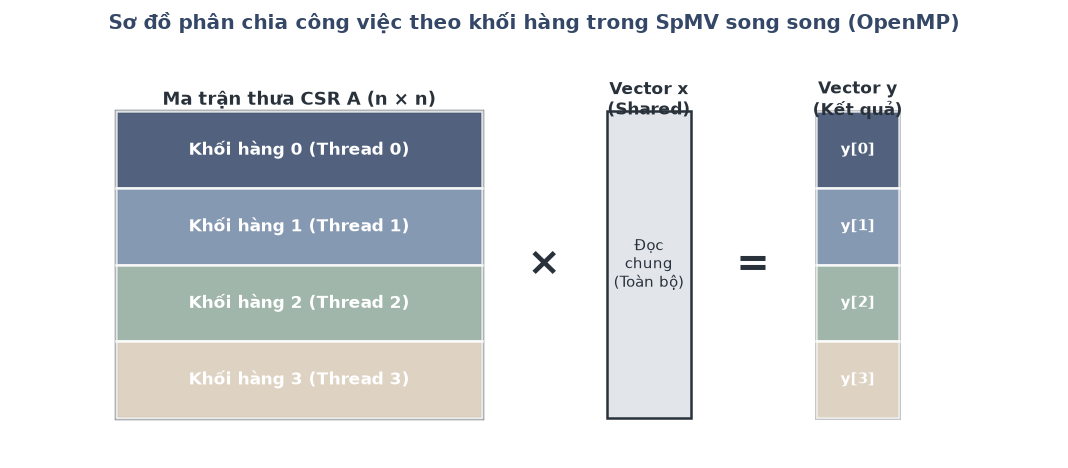

In [5]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw_row_partitioning_diagram():
    fig, ax = plt.subplots(figsize=(9, 4), dpi=120)
    colors = ['#344767', '#7187A5', '#8FA99B', '#D9CBB8']
    
    # Vẽ ma trận A
    ax.add_patch(patches.Rectangle((0.1, 0.1), 0.35, 0.8, fill=None, edgecolor='#29313B', linewidth=2))
    ax.text(0.275, 0.93, 'Ma trận thưa CSR A (n × n)', ha='center', va='center', fontsize=11, fontweight='bold', color='#29313B')
    
    for idx in range(4):
        y_bot = 0.1 + (3 - idx) * 0.2
        rect = patches.Rectangle((0.1, y_bot), 0.35, 0.2, facecolor=colors[idx], alpha=0.85, edgecolor='white', linewidth=1.5)
        ax.add_patch(rect)
        ax.text(0.275, y_bot + 0.1, f"Khối hàng {idx} (Thread {idx})", ha='center', va='center', color='white', fontweight='bold', fontsize=10)
    
    # Dấu nhân
    ax.text(0.51, 0.5, '×', ha='center', va='center', fontsize=24, fontweight='bold', color='#29313B')
    
    # Vector x
    ax.add_patch(patches.Rectangle((0.57, 0.1), 0.08, 0.8, facecolor='#E2E6EB', edgecolor='#29313B', linewidth=1.5))
    ax.text(0.61, 0.93, 'Vector x\n(Shared)', ha='center', va='center', fontsize=10, fontweight='bold', color='#29313B')
    ax.text(0.61, 0.5, 'Đọc\nchung\n(Toàn bộ)', ha='center', va='center', fontsize=9, color='#29313B')
    
    # Dấu bằng
    ax.text(0.71, 0.5, '=', ha='center', va='center', fontsize=24, fontweight='bold', color='#29313B')
    
    # Vector y kết quả
    ax.add_patch(patches.Rectangle((0.77, 0.1), 0.08, 0.8, fill=None, edgecolor='#29313B', linewidth=1.5))
    ax.text(0.81, 0.93, 'Vector y\n(Kết quả)', ha='center', va='center', fontsize=10, fontweight='bold', color='#29313B')
    for idx in range(4):
        y_bot = 0.1 + (3 - idx) * 0.2
        rect = patches.Rectangle((0.77, y_bot), 0.08, 0.2, facecolor=colors[idx], alpha=0.85, edgecolor='white', linewidth=1.5)
        ax.add_patch(rect)
        ax.text(0.81, y_bot + 0.1, f"y[{idx}]", ha='center', va='center', color='white', fontweight='bold', fontsize=9)
        
    ax.set_xlim(0, 1.0)
    ax.set_ylim(0, 1.05)
    ax.axis('off')
    plt.title("Sơ đồ phân chia công việc theo khối hàng trong SpMV song song (OpenMP)", fontsize=12, pad=15, color='#344767', fontweight='bold')
    plt.tight_layout()
    plt.show()

draw_row_partitioning_diagram()


## **3.6. Kiểm chứng tính chính xác (Correctness Verification)**

Quy trình kiểm chứng gồm 2 cấp độ:
1. **Kiểm tra trên ma trận nhỏ mẫu ($4 \times 4$):** So sánh trực tiếp kết quả với phép tính giải tích biết trước.
2. **Kiểm tra trên toàn bộ 5 ma trận thực nghiệm kích thước lớn ($20000 \dots 600000$):**
   - So sánh kết quả giữa `spmv_csr_parallel` với `spmv_csr_sequential` và với chuẩn `scipy.sparse.csr_matrix.dot`.
   - Tính sai số tuyệt đối cực đại $\max_i |y_{par}[i] - y_{ref}[i]|$ và sai số tương đối Euclid.


In [6]:
# 1. Kiểm tra trên ma trận nhỏ 4x4
small_A = sp.csr_matrix(np.array([
    [10.0, 1.0,  0.0, 2.0],
    [0.0,  8.0,  3.0, 0.0],
    [1.0,  0.0,  6.0, 1.0],
    [0.0,  2.0,  0.0, 9.0]
], dtype=np.float64))

small_x = np.array([1.0, 2.0, 3.0, 4.0], dtype=np.float64)
small_y_exact = np.array([20.0, 25.0, 23.0, 40.0], dtype=np.float64)

small_y_seq = np.zeros(4, dtype=np.float64)
small_y_par = np.zeros(4, dtype=np.float64)

spmv_csr_sequential(small_A.data, small_A.indices, small_A.indptr, small_x, small_y_seq, 4)
set_num_threads(2)
spmv_csr_parallel(small_A.data, small_A.indices, small_A.indptr, small_x, small_y_par, 4)

print("=== KIỂM CHỨNG MA TRẬN NHỎ 4x4 ===")
print("Nghiệm giải tích tính tay:     ", small_y_exact)
print("Kết quả SpMV tuần tự:          ", small_y_seq)
print("Kết quả SpMV song song (2 thr):", small_y_par)
print("Sai số cực đại (Par vs Exact): ", np.max(np.abs(small_y_par - small_y_exact)))
assert np.allclose(small_y_par, small_y_exact), "Kiểm tra ma trận nhỏ thất bại!"
print("=> KẾT QUẢ KIỂM CHỨNG MA TRẬN MẪU: CHÍNH XÁC TUYỆT ĐỐI!\n")

# 2. Kiểm chứng trên cả 5 ma trận kích thước lớn
validation_records = []

for n in matrix_sizes:
    mat = matrices[n]
    np.random.seed(100 + n)
    x = np.random.uniform(-1.0, 1.0, size=n).astype(np.float64)
    y_seq = np.zeros(n, dtype=np.float64)
    y_par = np.zeros(n, dtype=np.float64)
    
    spmv_csr_sequential(mat.data, mat.indices, mat.indptr, x, y_seq, n)
    set_num_threads(4)
    spmv_csr_parallel(mat.data, mat.indices, mat.indptr, x, y_par, n)
    y_scipy = mat.dot(x)
    
    max_err_seq = np.max(np.abs(y_par - y_seq))
    rel_err_seq = np.linalg.norm(y_par - y_seq) / np.linalg.norm(y_seq)
    max_err_scipy = np.max(np.abs(y_par - y_scipy))
    rel_err_scipy = np.linalg.norm(y_par - y_scipy) / np.linalg.norm(y_scipy)
    
    validation_records.append({
        "Ma trận": f"M_{n//1000}k",
        "Số hàng": n,
        "Sai số max (Par vs Seq)": f"{max_err_seq:.2e}",
        "Sai số tương đối (Par vs Seq)": f"{rel_err_seq:.2e}",
        "Sai số max (Par vs SciPy)": f"{max_err_scipy:.2e}",
        "Sai số tương đối (Par vs SciPy)": f"{rel_err_scipy:.2e}",
        "Kết luận": "ĐẠT CHUẨN" if rel_err_seq < 1e-12 else "KHÔNG ĐẠT"
    })

df_validation = pd.DataFrame(validation_records)
print("=== BẢNG KIỂM CHỨNG ĐỘ CHÍNH XÁC TRÊN 5 MA TRẬN (20k -> 600k) ===")
display(df_validation)


=== KIỂM CHỨNG MA TRẬN NHỎ 4x4 ===
Nghiệm giải tích tính tay:      [20. 25. 23. 40.]
Kết quả SpMV tuần tự:           [20. 25. 23. 40.]
Kết quả SpMV song song (2 thr): [20. 25. 23. 40.]
Sai số cực đại (Par vs Exact):  0.0
=> KẾT QUẢ KIỂM CHỨNG MA TRẬN MẪU: CHÍNH XÁC TUYỆT ĐỐI!

=== BẢNG KIỂM CHỨNG ĐỘ CHÍNH XÁC TRÊN 5 MA TRẬN (20k -> 600k) ===


,Ma trận,Số hàng,Sai số max (Par vs Seq),Sai số tương đối (Par vs Seq),Sai số max (Par vs SciPy),Sai số tương đối (Par vs SciPy),Kết luận
0,M_20k,20000,0.00e+00,0.00e+00,1.42e-14,1.62e-16,ĐẠT CHUẨN
1,M_60k,60000,0.00e+00,0.00e+00,1.42e-14,1.63e-16,ĐẠT CHUẨN
2,M_100k,100000,0.00e+00,0.00e+00,1.42e-14,1.63e-16,ĐẠT CHUẨN
3,M_200k,200000,0.00e+00,0.00e+00,1.42e-14,1.63e-16,ĐẠT CHUẨN
4,M_600k,600000,0.00e+00,0.00e+00,1.42e-14,1.63e-16,ĐẠT CHUẨN


## **3.7. Quy trình đo lường hiệu năng**

Quy trình chuẩn hóa:
1. Sử dụng `time.perf_counter()`.
2. Khởi động làm nóng (Warm-up 5 lần) để hoàn tất JIT và ổn định Cache.
3. Lặp lại 20 lần đo độc lập, lấy giá trị **Trung vị (Median)** làm $T(p)$ cốt lõi.


In [7]:
import time

def benchmark_spmv(spmv_func, mat, x, y, n, num_threads=1, warmups=5, trials=20):
    set_num_threads(num_threads)
    for _ in range(warmups):
        spmv_func(mat.data, mat.indices, mat.indptr, x, y, n)
        
    times = []
    for _ in range(trials):
        t_start = time.perf_counter()
        spmv_func(mat.data, mat.indices, mat.indptr, x, y, n)
        t_end = time.perf_counter()
        times.append(t_end - t_start)
        
    times = np.array(times)
    return {
        "median_sec": np.median(times),
        "mean_sec": np.mean(times),
        "std_sec": np.std(times),
        "min_sec": np.min(times),
        "max_sec": np.max(times)
    }

# Thử nghiệm mẫu quy trình đo với ma trận M_20k
mat_demo = matrices[20000]
x_demo = np.ones(20000, dtype=np.float64)
y_demo = np.zeros(20000, dtype=np.float64)

res_seq = benchmark_spmv(spmv_csr_sequential, mat_demo, x_demo, y_demo, 20000, num_threads=1)
res_par4 = benchmark_spmv(spmv_csr_parallel, mat_demo, x_demo, y_demo, 20000, num_threads=4)

print("=== KẾT QUẢ THỬ NGHIỆM QUY TRÌNH ĐO (Ma trận M_20k) ===")
print(f"Tuần tự (1 thread) : Trung vị = {res_seq['median_sec']*1000:.4f} ms, std = {res_seq['std_sec']*1000:.4f} ms")
print(f"Song song (4 threads): Trung vị = {res_par4['median_sec']*1000:.4f} ms, std = {res_par4['std_sec']*1000:.4f} ms")
print(f"Speedup tạm thời      : {res_seq['median_sec'] / res_par4['median_sec']:.2f}x")


=== KẾT QUẢ THỬ NGHIỆM QUY TRÌNH ĐO (Ma trận M_20k) ===
Tuần tự (1 thread) : Trung vị = 3.1965 ms, std = 0.8705 ms
Song song (4 threads): Trung vị = 1.4429 ms, std = 1.1929 ms
Speedup tạm thời      : 2.22x


### Sơ đồ quy trình đo lường tự động hóa
Quy trình tự động hóa thực nghiệm được tóm tắt qua lưu đồ sau:
```
[ Khởi tạo Ma trận CSR (N ∈ {20k, 60k, 100k, 200k, 600k}) ] 
                             │
                             ▼
                 [ Khởi tạo Vector x, y ]
                             │
                             ▼
              [ Cấu hình Số luồng p ∈ {1, 2, 4, 5, 6, 7, 8} ]
                             │
                             ▼
              [ Khởi động (Warm-up 5 lần) ]  ──► (Biên dịch JIT LLVM, nạp Cache)
                             │
                             ▼
               [ Vòng lặp đo lường 20 lần ]  ──► (perf_counter() ghi nhận T)
                             │
                             ▼
               [ Tính Median, Mean, Std ]
                             │
                             ▼
              [ Xuất bảng CSV & Trực quan hóa ]
```
